# 💳 Credit Card Fraud Detection



## 1. Setup

In [1]:
import os
import kagglehub
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.decomposition import PCA
from sklearn.metrics import (average_precision_score, roc_auc_score, precision_score,
                             recall_score, f1_score, matthews_corrcoef, confusion_matrix,
                             precision_recall_curve, ConfusionMatrixDisplay)

import tensorflow as tf
from tensorflow import keras

RANDOM_STATE = 42
keras.utils.set_random_seed(RANDOM_STATE)
os.makedirs("figures", exist_ok=True)

## 2. Load the data

**Dataset:** [Credit Card Fraud Detection (Kaggle, ULB)](https://www.kaggle.com/datasets/mlg-ulb/creditcardfraud) —
284,807 transactions made by European cardholders over two days in September 2013, of which 492 are frauds.

| Column | Meaning |
|---|---|
| `V1`–`V28` | Anonymised features (PCA components of the original confidential data) |
| `Time` | Seconds elapsed since the first transaction in the dataset |
| `Amount` | Transaction amount |
| `Class` | Target: 1 = fraud, 0 = normal |

In [2]:
if os.path.exists("creditcard.csv"):
    os.remove("creditcard.csv")

dataset_path = kagglehub.dataset_download("mlg-ulb/creditcardfraud")
DATA_FILE = os.path.join(dataset_path, "creditcard.csv")

df = pd.read_csv(DATA_FILE)
assert len(df) == 284_807, f"incomplete file: {len(df):,} rows"
print("Shape:", df.shape)
df.head()

Using Colab cache for faster access to the 'creditcardfraud' dataset.
Shape: (284807, 31)


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


## 3. Exploratory data analysis

In [3]:
print("Missing values:", int(df.isna().sum().sum()))
print("Duplicate rows:", int(df.duplicated().sum()))

class_counts = df["Class"].value_counts().sort_index()
print("\nClass counts:")
print(class_counts.rename({0: "Normal", 1: "Fraud"}))
fraud_rate = class_counts[1] / len(df)
print(f"\nFraud rate: {fraud_rate:.4%}")
print(f"A model that ALWAYS predicts 'normal' would score {1 - fraud_rate:.2%} accuracy "
      "while catching zero frauds -> accuracy is the wrong metric here.")

Missing values: 0
Duplicate rows: 1081

Class counts:
Class
Normal    284315
Fraud        492
Name: count, dtype: int64

Fraud rate: 0.1727%
A model that ALWAYS predicts 'normal' would score 99.83% accuracy while catching zero frauds -> accuracy is the wrong metric here.


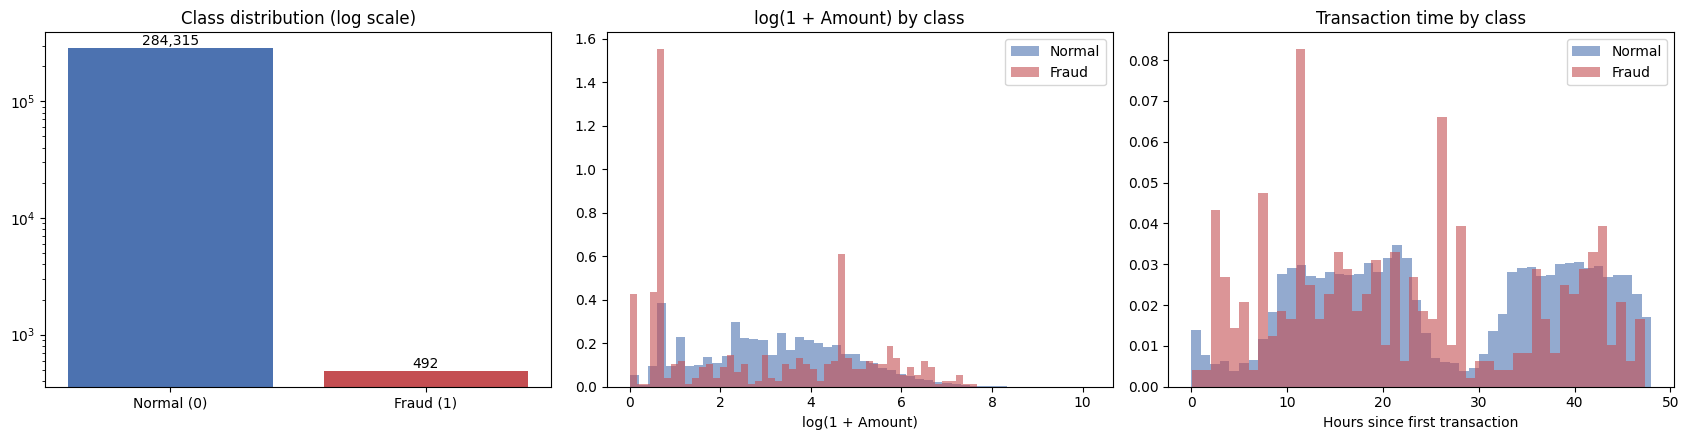

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))

axes[0].bar(["Normal (0)", "Fraud (1)"], class_counts.values, color=["#4C72B0", "#C44E52"])
axes[0].set_yscale("log")
axes[0].set_title("Class distribution (log scale)")
for i, v in enumerate(class_counts.values):
    axes[0].text(i, v, f"{v:,}", ha="center", va="bottom")

for label, color, name in [(0, "#4C72B0", "Normal"), (1, "#C44E52", "Fraud")]:
    subset = df[df["Class"] == label]
    axes[1].hist(np.log1p(subset["Amount"]), bins=50, density=True, alpha=0.6, color=color, label=name)
    axes[2].hist(subset["Time"] / 3600, bins=48, density=True, alpha=0.6, color=color, label=name)

axes[1].set_title("log(1 + Amount) by class")
axes[1].set_xlabel("log(1 + Amount)")
axes[1].legend()
axes[2].set_title("Transaction time by class")
axes[2].set_xlabel("Hours since first transaction")
axes[2].legend()

plt.tight_layout()
plt.savefig("figures/eda_overview.png", dpi=150, bbox_inches="tight")
plt.show()

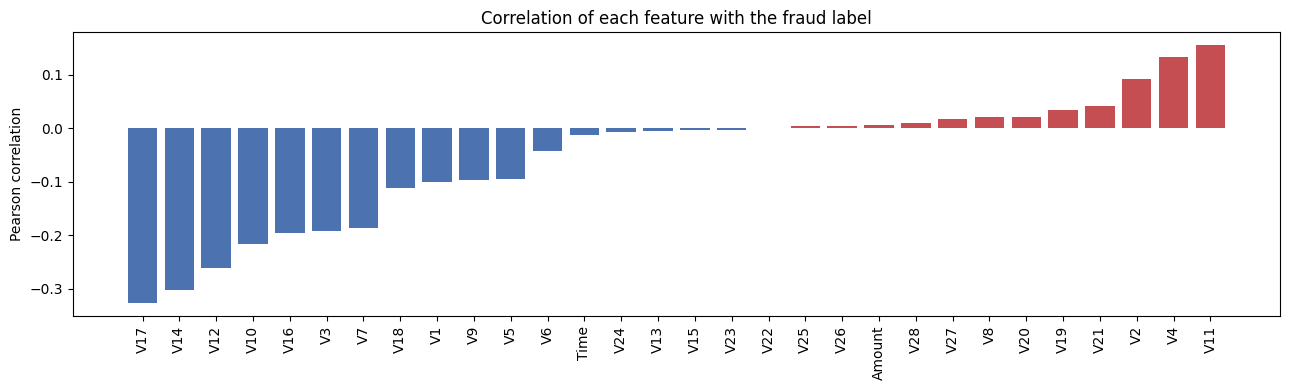

In [5]:
correlations = df.drop(columns="Class").corrwith(df["Class"]).sort_values()

plt.figure(figsize=(13, 4))
plt.bar(correlations.index, correlations.values,
        color=np.where(correlations.values > 0, "#C44E52", "#4C72B0"))
plt.xticks(rotation=90)
plt.title("Correlation of each feature with the fraud label")
plt.ylabel("Pearson correlation")
plt.tight_layout()
plt.savefig("figures/feature_correlation.png", dpi=150, bbox_inches="tight")
plt.show()

**EDA findings**

- No missing values.
- 1,081 duplicate rows (19 frauds) → removed before splitting.
- Fraud rate 0.17% → stratified split, evaluate with PR-AUC, precision, recall, F1.
- `Amount` is skewed → log(1 + Amount).
- V1–V28 have different scales → standardise all features.
- `Time` is seconds since the first transaction → dropped.

## 4. Preprocessing

Train / validation / test = 64 / 16 / 20, stratified. Validation is used for early stopping and thresholds, test only for the final results.

In [6]:
data = df.drop_duplicates().reset_index(drop=True)
print(f"{len(data):,} rows after removing duplicates, {int(data['Class'].sum())} frauds")

X = data.drop(columns=["Time", "Class"])
y = data["Class"].astype(int)
FEATURES = X.columns.tolist()

X_train_full, X_test, y_train_full, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
X_train, X_val, y_train, y_val = train_test_split(
    X_train_full, y_train_full, test_size=0.2, stratify=y_train_full, random_state=RANDOM_STATE)

for name, labels in [("Train", y_train), ("Validation", y_val), ("Test", y_test)]:
    print(f"{name:<11} {len(labels):>7,} rows | frauds: {labels.sum():>3}")

283,726 rows after removing duplicates, 473 frauds
Train       181,584 rows | frauds: 302
Validation   45,396 rows | frauds:  76
Test         56,746 rows | frauds:  95


In [7]:
def log_amount(frame):
    frame = frame.copy()
    frame["Amount"] = np.log1p(frame["Amount"])
    return frame

scaler = StandardScaler().fit(log_amount(X_train))

def prepare(frame):
    return scaler.transform(log_amount(frame)).astype("float32")

X_train_s = prepare(X_train)
X_val_s = prepare(X_val)
X_test_s = prepare(X_test)

In [8]:
results = {}
pr_curves = {}

def best_f1_threshold(y_true, scores):
    precision, recall, thresholds = precision_recall_curve(y_true, scores)
    f1 = 2 * precision * recall / (precision + recall + 1e-12)
    best = np.argmax(f1[:-1])
    return thresholds[best]

def evaluate(name, y_true, scores, threshold):
    y_pred = (scores >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
    results[name] = {
        "PR-AUC": average_precision_score(y_true, scores),
        "ROC-AUC": roc_auc_score(y_true, scores),
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "Recall": recall_score(y_true, y_pred),
        "F1": f1_score(y_true, y_pred),
        "MCC": matthews_corrcoef(y_true, y_pred),
        "TP": tp, "FP": fp, "FN": fn, "TN": tn,
    }
    precision, recall, _ = precision_recall_curve(y_true, scores)
    pr_curves[name] = (recall, precision)

    print(name)
    for k in ["PR-AUC", "ROC-AUC", "Precision", "Recall", "F1", "MCC"]:
        print(f"  {k:<10} {results[name][k]:.4f}")
    print(f"  caught {tp}/{tp + fn} frauds, {fp} false alarms")

    fig, ax = plt.subplots(figsize=(4.5, 4))
    ConfusionMatrixDisplay.from_predictions(y_true, y_pred, display_labels=["Normal", "Fraud"],
                                            cmap="Blues", values_format=",", ax=ax, colorbar=False)
    ax.set_title(name)
    plt.tight_layout()
    plt.savefig(f"figures/cm_{name.lower().replace(' ', '_')}.png", dpi=150, bbox_inches="tight")
    plt.show()

## 5. Random Forest (baseline)

Supervised, uses the labels. Threshold chosen on validation (best F1).

threshold: 0.490
Random Forest
  PR-AUC     0.8136
  ROC-AUC    0.9385
  Precision  0.9710
  Recall     0.7053
  F1         0.8171
  MCC        0.8273
  caught 67/95 frauds, 2 false alarms


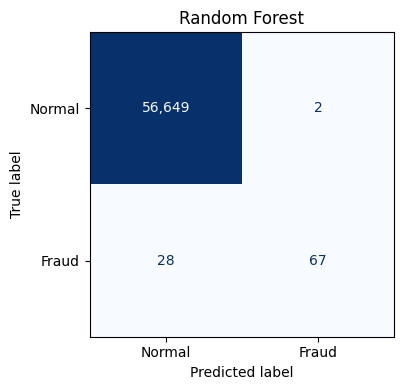

In [9]:
rf = RandomForestClassifier(
    n_estimators=200,
    class_weight="balanced_subsample",
    min_samples_leaf=2,
    n_jobs=-1,
    random_state=RANDOM_STATE,
)
rf.fit(X_train_s, y_train)

rf_val = rf.predict_proba(X_val_s)[:, 1]
rf_test = rf.predict_proba(X_test_s)[:, 1]
rf_threshold = best_f1_threshold(y_val, rf_val)
print(f"threshold: {rf_threshold:.3f}")

evaluate("Random Forest", y_test, rf_test, rf_threshold)

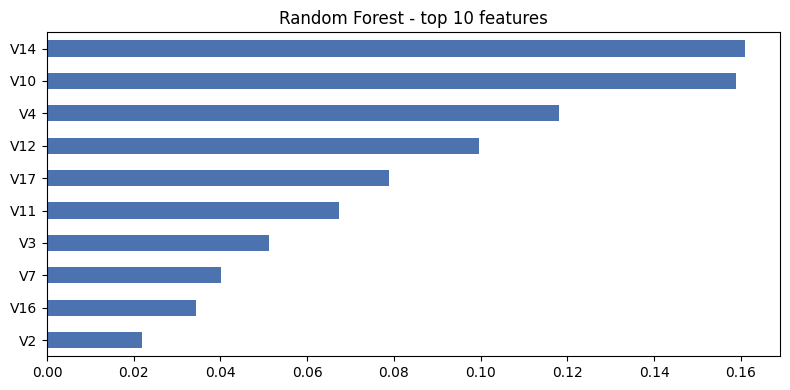

In [10]:
importances = pd.Series(rf.feature_importances_, index=FEATURES).sort_values(ascending=False).head(10)

plt.figure(figsize=(8, 4))
importances[::-1].plot.barh(color="#4C72B0")
plt.title("Random Forest - top 10 features")
plt.tight_layout()
plt.savefig("figures/rf_feature_importance.png", dpi=150, bbox_inches="tight")
plt.show()

## 6. Autoencoder

Trained on normal transactions only. Fraud score = reconstruction error.

29 → 24 → 16 → 8 → 16 → 24 → 29 (best validation PR-AUC in section 8)

In [11]:
X_train_normal = X_train_s[y_train.values == 0]
X_val_normal = X_val_s[y_val.values == 0]
print("normal train:", X_train_normal.shape, "| normal val:", X_val_normal.shape)

normal train: (181282, 29) | normal val: (45320, 29)


### 6.1 Build

In [12]:
INPUT_DIM = X_train_s.shape[1]

def build_autoencoder(latent_dim=8, hidden_layers=(24, 16)):
    input_layer = keras.layers.Input(shape=(INPUT_DIM,))

    encoded = input_layer
    for units in hidden_layers:
        encoded = keras.layers.Dense(units, activation="relu")(encoded)
    encoded = keras.layers.Dense(latent_dim, activation="relu", name="latent")(encoded)

    decoded = encoded
    for units in reversed(hidden_layers):
        decoded = keras.layers.Dense(units, activation="relu")(decoded)
    decoded = keras.layers.Dense(INPUT_DIM, activation="linear")(decoded)

    autoencoder = keras.Model(input_layer, decoded)
    encoder = keras.Model(input_layer, encoded)
    autoencoder.compile(optimizer="adam", loss="mse")
    return autoencoder, encoder

def callbacks():
    return [
        keras.callbacks.EarlyStopping(monitor="val_loss", patience=8, restore_best_weights=True),
        keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=3),
    ]

autoencoder, encoder = build_autoencoder(latent_dim=8, hidden_layers=(24, 16))
autoencoder.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 29)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 24)             │           720 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 16)             │           400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ latent (Dense)                  │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 16)             │           144 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 24)             │           408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 29)             │           725 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,533 (9.89 KB)

 Trainable params: 2,533 (9.89 KB)

 Non-trainable params: 0 (0.00 B)

### 6.2 Train

epochs: 150 | best val loss: 0.2751


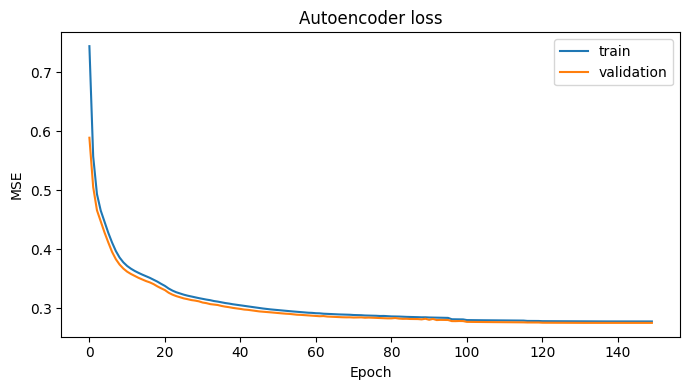

In [13]:
history = autoencoder.fit(
    X_train_normal, X_train_normal,
    epochs=150,
    batch_size=256,
    shuffle=True,
    validation_data=(X_val_normal, X_val_normal),
    callbacks=callbacks(),
    verbose=0,
)
print(f"epochs: {len(history.history['loss'])} | best val loss: {min(history.history['val_loss']):.4f}")

plt.figure(figsize=(7, 4))
plt.plot(history.history["loss"], label="train")
plt.plot(history.history["val_loss"], label="validation")
plt.xlabel("Epoch"); plt.ylabel("MSE"); plt.title("Autoencoder loss")
plt.legend(); plt.tight_layout()
plt.savefig("figures/ae_loss.png", dpi=150, bbox_inches="tight")
plt.show()

### 6.3 Latent space

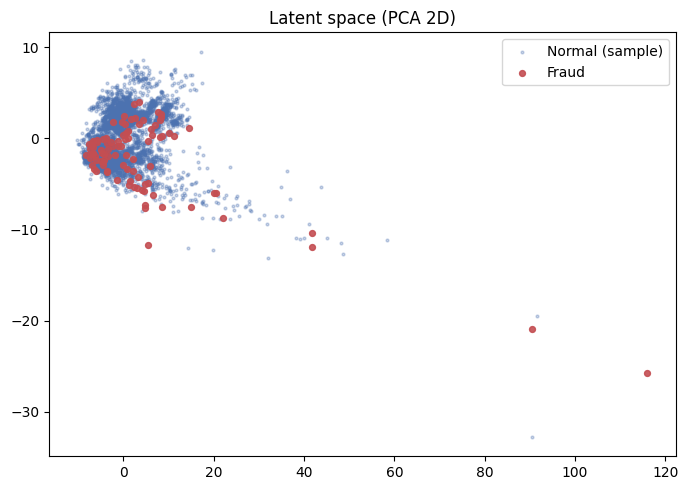

In [14]:
latent_test = encoder.predict(X_test_s, verbose=0)
latent_2d = PCA(n_components=2, random_state=RANDOM_STATE).fit_transform(latent_test)

normal_idx = np.where(y_test.values == 0)[0]
normal_idx = np.random.default_rng(RANDOM_STATE).choice(normal_idx, size=5000, replace=False)
fraud_idx = np.where(y_test.values == 1)[0]

plt.figure(figsize=(7, 5))
plt.scatter(*latent_2d[normal_idx].T, s=4, alpha=0.3, color="#4C72B0", label="Normal (sample)")
plt.scatter(*latent_2d[fraud_idx].T, s=18, alpha=0.9, color="#C44E52", label="Fraud")
plt.title("Latent space (PCA 2D)")
plt.legend(); plt.tight_layout()
plt.savefig("figures/ae_latent_space.png", dpi=150, bbox_inches="tight")
plt.show()

### 6.4 Reconstruction error

mean error normal: 0.280
mean error fraud:  15.814
threshold:         4.023


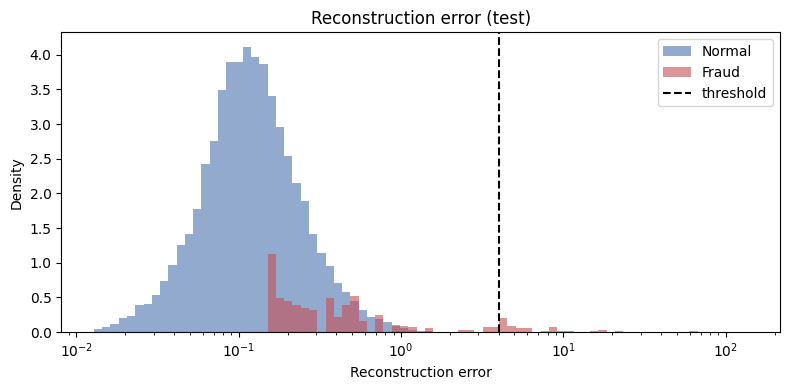

In [15]:
def reconstruction_error(model, X):
    reconstructed = model.predict(X, batch_size=4096, verbose=0)
    return np.mean((X - reconstructed) ** 2, axis=1)

val_err = reconstruction_error(autoencoder, X_val_s)
test_err = reconstruction_error(autoencoder, X_test_s)
ae_threshold = best_f1_threshold(y_val, val_err)

print(f"mean error normal: {test_err[y_test.values == 0].mean():.3f}")
print(f"mean error fraud:  {test_err[y_test.values == 1].mean():.3f}")
print(f"threshold:         {ae_threshold:.3f}")

bins = np.logspace(np.log10(test_err.min()), np.log10(test_err.max()), 80)
plt.figure(figsize=(8, 4))
plt.hist(test_err[y_test.values == 0], bins=bins, density=True, alpha=0.6, color="#4C72B0", label="Normal")
plt.hist(test_err[y_test.values == 1], bins=bins, density=True, alpha=0.6, color="#C44E52", label="Fraud")
plt.axvline(ae_threshold, color="k", ls="--", label="threshold")
plt.xscale("log")
plt.xlabel("Reconstruction error"); plt.ylabel("Density")
plt.title("Reconstruction error (test)")
plt.legend(); plt.tight_layout()
plt.savefig("figures/ae_error_distribution.png", dpi=150, bbox_inches="tight")
plt.show()

### 6.5 Results

Autoencoder
  PR-AUC     0.5107
  ROC-AUC    0.9503
  Precision  0.5508
  Recall     0.6842
  F1         0.6103
  MCC        0.6132
  caught 65/95 frauds, 53 false alarms


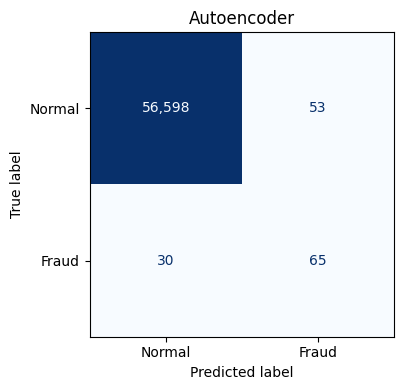

In [16]:
evaluate("Autoencoder", y_test, test_err, ae_threshold)

## 7. Denoising Autoencoder

Gaussian noise (0.2) on the input, clean data as target.

Denoising AE
  PR-AUC     0.3953
  ROC-AUC    0.9377
  Precision  0.4419
  Recall     0.4000
  F1         0.4199
  MCC        0.4195
  caught 38/95 frauds, 48 false alarms


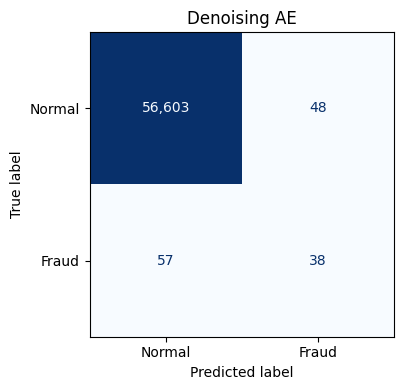

In [17]:
NOISE_FACTOR = 0.2
rng = np.random.default_rng(RANDOM_STATE)
X_train_normal_noisy = X_train_normal + NOISE_FACTOR * rng.normal(size=X_train_normal.shape).astype("float32")
X_val_normal_noisy = X_val_normal + NOISE_FACTOR * rng.normal(size=X_val_normal.shape).astype("float32")

denoiser, _ = build_autoencoder(latent_dim=8, hidden_layers=(24, 16))
denoiser.fit(
    X_train_normal_noisy, X_train_normal,
    epochs=150, batch_size=256, shuffle=True,
    validation_data=(X_val_normal_noisy, X_val_normal),
    callbacks=callbacks(),
    verbose=0,
)

dae_val_err = reconstruction_error(denoiser, X_val_s)
dae_test_err = reconstruction_error(denoiser, X_test_s)
dae_threshold = best_f1_threshold(y_val, dae_val_err)

evaluate("Denoising AE", y_test, dae_test_err, dae_threshold)

## 8. Latent size and depth

Compared on validation PR-AUC.

In [18]:
experiments = {
    "29-16-4":       dict(latent_dim=4,  hidden_layers=(16,)),
    "29-16-8":       dict(latent_dim=8,  hidden_layers=(16,)),
    "29-22-16":      dict(latent_dim=16, hidden_layers=(22,)),
    "29-24-16-8":    dict(latent_dim=8,  hidden_layers=(24, 16)),
    "29-24-16-12-8": dict(latent_dim=8,  hidden_layers=(24, 16, 12)),
}

rows = []
for name, config in experiments.items():
    model, _ = build_autoencoder(**config)
    model.fit(
        X_train_normal, X_train_normal,
        epochs=150, batch_size=256, shuffle=True,
        validation_data=(X_val_normal, X_val_normal),
        callbacks=callbacks(),
        verbose=0,
    )
    err = reconstruction_error(model, X_val_s)
    rows.append({
        "Architecture": name,
        "Params": model.count_params(),
        "Val loss (normal)": float(np.mean(err[y_val.values == 0])),
        "Val PR-AUC": average_precision_score(y_val, err),
        "Val ROC-AUC": roc_auc_score(y_val, err),
    })
    print("done:", name)

experiments_table = pd.DataFrame(rows).set_index("Architecture").round(4)
experiments_table

done: 29-16-4
done: 29-16-8
done: 29-22-16
done: 29-24-16-8
done: 29-24-16-12-8


,Params,Val loss (normal),Val PR-AUC,Val ROC-AUC
Architecture,,,,
29-16-4,1121,0.5117,0.3732,0.9545
29-16-8,1253,0.4029,0.3554,0.9442
29-22-16,2069,0.2818,0.3447,0.9345
29-24-16-8,2533,0.2877,0.6623,0.9541
29-24-16-12-8,2877,0.3199,0.6472,0.9442


## 9. Comparison (test set)

In [19]:
comparison = pd.DataFrame(results).T
display(comparison[["PR-AUC", "ROC-AUC", "Precision", "Recall", "F1", "MCC"]].astype(float).round(4))
display(comparison[["TP", "FP", "FN", "TN"]].astype(int))

,PR-AUC,ROC-AUC,Precision,Recall,F1,MCC
Random Forest,0.8136,0.9385,0.9710,0.7053,0.8171,0.8273
Autoencoder,0.5107,0.9503,0.5508,0.6842,0.6103,0.6132
Denoising AE,0.3953,0.9377,0.4419,0.4000,0.4199,0.4195


,TP,FP,FN,TN
Random Forest,67,2,28,56649
Autoencoder,65,53,30,56598
Denoising AE,38,48,57,56603


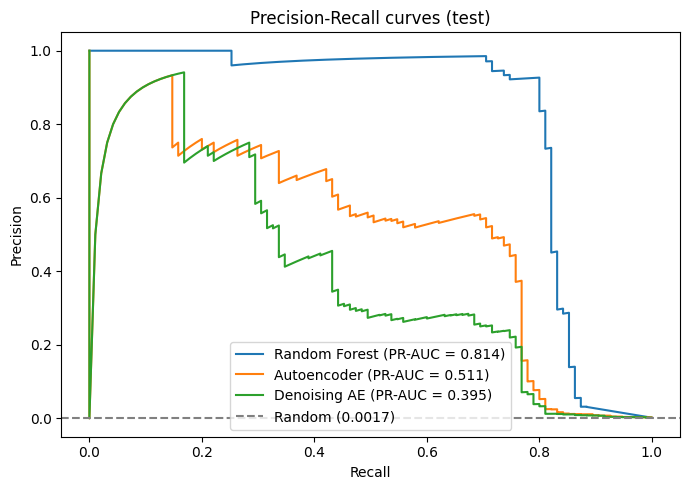

In [20]:
plt.figure(figsize=(7, 5))
for name, (recall, precision) in pr_curves.items():
    plt.plot(recall, precision, label=f"{name} (PR-AUC = {results[name]['PR-AUC']:.3f})")
plt.axhline(y_test.mean(), color="grey", linestyle="--", label=f"Random ({y_test.mean():.4f})")
plt.xlabel("Recall"); plt.ylabel("Precision")
plt.title("Precision-Recall curves (test)")
plt.legend(); plt.tight_layout()
plt.savefig("figures/pr_curves_comparison.png", dpi=150, bbox_inches="tight")
plt.show()

## 10. Findings


*   The data is highly imbalanced (0.17% fraud), so accuracy is not used. PR-AUC is the main metric.
*   Random Forest is the best model: PR-AUC 0.81, caught 67 of 95 frauds with only 2 false alarms.


*   Autoencoder (29-24-16-8): PR-AUC 0.51, caught 65 of 95 frauds, close to Random Forest, but with 53 false alarms.
*   Denoising AE did not help: PR-AUC 0.40, caught 38 of 95 frauds.


*   A deeper encoder (29-24-16-8) worked much better than a shallow one (validation PR-AUC 0.66 vs 0.36).
*   Lower reconstruction loss does not mean better detection: 29-22-16 had the lowest loss but one of the lowest PR-AUC scores.

*   ROC-AUC is high for every model (0.94–0.95), so it does not show the real differences on imbalanced data.
*   The autoencoder does not use labels, which helps when labels are missing or fraud patterns change.

*   The test set has only 95 frauds, so small differences between models can be noise.









